# Train an NZ vegetation classifier for VedgeSat

A New Zealand version of `train_new_classifier_veg.ipynb`. The original notebook and all `Toolshed` files are left untouched.

**What this notebook does**

1. Fetches your chosen Landsat 8 and Sentinel-2 scenes for each training site, scene by scene.
2. Labels them with subclasses (e.g. `dune_veg`, `sand_dry`) that are collapsed to veg / non-veg for training.
3. Builds a balanced training set: equal pixels per site and platform, with a fixed share per subclass.
4. Evaluates with leave-one-site-out, and scores the **default** VedgeSat model on the same NZ pixels for a direct comparison.
5. Trains and saves two models: one with `sparse_veg` counted as vegetation, one without.

**Workflow**

- Run Section 0 once and read the checks before labelling anything.
- Fill in Section 1 from your selection log.
- Label **one site at a time** in Section 2, then run Section 3 after the very first scene to confirm what was saved.
- Sections 4 to 6 run once all sites are labelled.

This notebook lives in the `Classification` folder, like the original.

## 0. Setup and checks

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, glob, json, pickle, inspect, warnings
from datetime import datetime
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.neural_network import MLPClassifier
import joblib

sys.path.insert(0, os.pardir)
from collections import defaultdict
from Toolshed import Toolbox, Download, Classifier, Image_Processing, VegetationLine

import ee
ee.Initialize(project='civic-ripsaw-454707-c4')

# Paths (notebook sits in COASTGUARD-master/Classification)
filepath_train  = os.path.join(os.getcwd(), 'training_data')
filepath_models = os.path.join(os.getcwd(), 'models')
filepath_data   = os.path.join(os.getcwd(), os.pardir, 'Data')
for p in [filepath_train, filepath_models, filepath_data]:
    os.makedirs(p, exist_ok=True)

# Subclasses used while labelling. Integer IDs only matter to the labeller.
# Collapse to veg / non-veg happens in Section 4.
LABELS = {
    'dune_veg':    1,   # marram, spinifex, pingao: green AND tan/dry
    'other_veg':   2,   # pasture, bush, pine, flax, lawns, saltmarsh/mangrove
    'sparse_veg':  3,   # clumps over mostly bare sand (the ambiguous fringe)
    'sand_dry':    4,   # dry sand, dark or pale
    'sand_wet':    5,   # wet sand, swash zone, mudflat
    'water':       6,   # sea, surf, rivers, lagoons (keep polygons small)
    'shadow_rock': 7,   # cliff/dune/cloud shadow, rock, cliff faces
    'built_cloud': 8,   # roads, car parks, large roofs, cloud, haze
}
COLORS = {
    'dune_veg':    [0.85, 0.75, 0.35],
    'other_veg':   [0.20, 0.60, 0.20],
    'sparse_veg':  [0.60, 0.85, 0.40],
    'sand_dry':    [0.95, 0.60, 0.20],
    'sand_wet':    [0.55, 0.35, 0.20],
    'water':       [0.30, 0.45, 0.90],
    'shadow_rock': [0.40, 0.40, 0.40],
    'built_cloud': [0.90, 0.30, 0.70],
}

settings = {
    'filepath_train': filepath_train,
    'cloud_thresh': 0.7,          # lenient: scenes are hand-picked as clear over the AOI
    'cloud_mask_issue': False,
    'inputs': {'filepath': filepath_data},
    'labels': LABELS,
    'colors': COLORS,
}
print('sklearn', sklearn.__version__)

sklearn 1.7.2


**Checks.** The labeller in this notebook is a copy of the authors' `Classifier.label_vegimages`, extended to subclasses. It calls `Image_Processing.preprocess_single` the current way (as `extract_veglines` does) and computes features with `VegetationLine.calculate_vegfeatures`, so training features match extraction. This cell confirms your Toolshed has those functions in the expected form.

In [2]:
sig = inspect.signature(Image_Processing.preprocess_single)
print('preprocess_single', sig)
print('  current signature (starts with ImgColl):', list(sig.parameters)[0] == 'ImgColl')
print('label_vegimages present:', hasattr(Classifier, 'label_vegimages'))
print('SelectFromImage present:', hasattr(Classifier, 'SelectFromImage'))
print('calculate_vegfeatures present:', hasattr(VegetationLine, 'calculate_vegfeatures'))

preprocess_single (ImgColl, georef, fn, datelist, filenames, satname, settings, polygon, dates, skipped)
  current signature (starts with ImgColl): True
label_vegimages present: True
SelectFromImage present: True
calculate_vegfeatures present: True


## 1. Sites and scenes

Fill this in from your selection log. `role` is `'train'` for training sites or `'test'` for optional test-only scenes at your validation sites (never used for training).

- `bbox`: `(lonmin, lonmax, latmin, latmax)` in WGS84, under ~5 km across.
- `scenes`: dates as `'YYYY-MM-DD'`, per platform.
- `tile`: the Sentinel-2 tile you chose for that site (e.g. `'T60HTE'`), used to flag duplicates.

In [3]:
SITES = {
    'TeHenga':             {'role': 'train', 'bbox': (174.43008, 174.47472, -36.90844, -36.86801), 'tile': 'T60HTE',
                            'scenes': {'S2': ['2024-03-18',     # Late summer
                                              '2024-09-04'],    # Winter
                                       'L8': ['2024-03-15',     # Late summer
                                              '2024-09-07']}},  # Winter
    'Kawhia':              {'role': 'train', 'bbox': (174.76064, 174.80974, -38.08386, -38.03845), 'tile': None,
                            'scenes': {'S2': ['2024-02-27',     # Late summer
                                              '2024-08-10'],    # Winter
                                       'L8': ['2024-03-24',     # Late summer
                                              '2024-07-30']}},  # Winter
    'TeArai':              {'role': 'train','bbox': (174.62572, 174.66877, -36.18858, -36.13931), 'tile': None,
                            'scenes': {'S2': ['2024-03-18',     # Late summer
                                              '2024-07-11'],    # Winter
                                       'L8': ['2024-02-21',     # Late summer
                                              '2024-06-28']}},  # Winter
    'NorthNewBrighton':    {'role': 'train', 'bbox': (172.69480, 172.74621, -43.50614, -43.47008), 'tile': None,
                            'scenes': {'S2': ['2025-02-16',     # Late summer
                                              '2025-09-09'],    # Winter
                                       'L8': ['2025-02-23',     # Late summer
                                              '2025-07-24']}},  # Winter
    # Optional test-only scenes at validation sites:
    # 'TEST_Muriwai':  {'role': 'test', 'bbox': None, 'tile': None, 'scenes': {'S2': [], 'L8': []}},
    # 'TEST_Karekare': {'role': 'test', 'bbox': None, 'tile': None, 'scenes': {'S2': [], 'L8': []}},
    # 'TEST_Pakiri':   {'role': 'test', 'bbox': None, 'tile': None, 'scenes': {'S2': [], 'L8': []}},
}

for name, s in SITES.items():
    n = {p: len(d) for p, d in s['scenes'].items()}
    status = 'OK' if s['bbox'] else 'bbox missing'
    print(f"{name:20s} {s['role']:5s} {status:13s} tile={s['tile']}  scenes {n}")

TeHenga              train OK            tile=T60HTE  scenes {'S2': 2, 'L8': 2}
Kawhia               train OK            tile=None  scenes {'S2': 2, 'L8': 2}
TeArai               train OK            tile=None  scenes {'S2': 2, 'L8': 2}
NorthNewBrighton     train OK            tile=None  scenes {'S2': 2, 'L8': 2}


## 2. Fetch and label one scene at a time

Set `SITE`, `PLATFORM` and `SCENE` (0 = first date in the list, 1 = second), run the fetch cell, check the printout, then run the labeller.

- The fetch uses a one-day window, so it returns only that date. Earth Engine dates are UTC: if a date returns nothing, try the day before.
- If a `tile` is set for the site, other Sentinel-2 tiles from the same pass are removed before labelling.

**Labeller controls** (as in the authors' `label_vegimages`):

- **→** keep and label this image, **←** skip it, **Esc** stop labelling.
- For each subclass in turn: click and drag to draw lassos around pixels, as many as you like. **Enter** = done, move to the next subclass (press Enter straight away to skip a subclass that isn't present). **Esc** = clear this subclass's lassos and start it again.
- If lassos for two subclasses overlap, the later subclass wins.
- After the last subclass, a JPG of your labels and the `.pkl` are saved to `training_data/<site>_train/`, and the pixel count per subclass is printed. Compare it with your per-scene targets.

Labelling rules (from the protocol):

- Label **interiors**; keep at least one pixel clear of the dune toe (two or three where no matching aerial exists).
- Dune vegetation of **every colour** is the top priority, including dry tan marram and orange pīngao.
- `sparse_veg`: clumps over mostly bare sand. Label vegetation-dominated pixels as `dune_veg`; skip pixels you can't call.
- Keep `water` polygons small. Label bare dark sand between clumps as `sand_dry` where gaps span two or more pixels.
- Skip features narrower than about two pixels, mixed suburban blocks, and seagrass or algae-covered flats.

In [37]:
from datetime import timedelta

SITE = 'NorthNewBrighton'
PLATFORM = 'L8'          # 'S2' or 'L8'
SCENE = 1                # 0 = first date in the list, 1 = second

site = SITES[SITE]
assert site['bbox'], f'Fill in the bbox for {SITE} in Section 1'
dates = sorted(site['scenes'][PLATFORM])
assert dates, f'No {PLATFORM} dates listed for {SITE}'
d = dates[SCENE]
d_next = (datetime.strptime(d, '%Y-%m-%d') + timedelta(days=1)).strftime('%Y-%m-%d')

sitename = f'{SITE}_train' if site['role'] == 'train' else SITE
os.makedirs(os.path.join(os.getcwd(), 'Data'), exist_ok=True)              # parent folder VedgeSat expects
filepath_site = Toolbox.CreateFileStructure(sitename, [PLATFORM])           # creates ./Data/<sitename>/, as the driver does
os.makedirs(os.path.join(os.getcwd(), 'Data', sitename), exist_ok=True)    # make sure the site folder exists

lonmin, lonmax, latmin, latmax = site['bbox']
polygon, point = Toolbox.AOI(lonmin, lonmax, latmin, latmax, sitename)
polygon = Toolbox.smallest_rectangle(polygon)

# Coordinate systems, as the driver sets them
settings['ref_epsg'] = 4326                                                  # bbox is in WGS84 lon/lat
settings['projection_epsg'], _ = Toolbox.FindUTM(polygon[0][0][1], polygon[0][0][0])   # local UTM zone
settings['output_epsg'] = settings['projection_epsg']

# One-day window: start date included, end date excluded, so this returns just that day
inputs = {'polygon': polygon, 'dates': [d, d_next], 'daterange': 'yes',
          'sat_list': [PLATFORM], 'sitename': sitename, 'filepath': filepath_site}
inputs = Download.check_images_available(inputs)
inputs['sat_list'] = [PLATFORM]          # restore: the availability check can drop the platform

Sat = Download.RetrieveImages(inputs)

# VedgeSat caches the image list per site and reloads it whatever the dates, so clear it for each scene
for folder in {os.path.join(filepath_site, sitename), os.path.join(os.getcwd(), 'Data', sitename)}:
    for f in glob.glob(os.path.join(folder, '**', '*metadata*'), recursive=True):
        os.remove(f)
        print('cleared cached metadata:', os.path.relpath(f))

metadata = Download.CollectMetadata(inputs, Sat)
settings['inputs'] = inputs

# Keep only the chosen Sentinel-2 tile (images are built from these filenames, so this is all that's needed)
if PLATFORM == 'S2' and site['tile']:
    md_s2 = metadata['S2']
    n = len(md_s2['filenames'])
    keep = [i for i, f in enumerate(md_s2['filenames']) if site['tile'] in str(f)]
    for key, val in md_s2.items():
        if isinstance(val, list) and len(val) == n:
            md_s2[key] = [val[i] for i in keep]

print(f'\n{SITE} {PLATFORM}: requested {d}; to be labelled:')
for f in metadata[PLATFORM]['filenames']:
    print('  ', f)
if not metadata[PLATFORM]['filenames']:
    print('   nothing left: check the date (UTC, try the day before) or the tile code')

Images available between 2025-07-24 and 2025-07-25:
- In Landsat Tier 1 & Sentinel-2 Level-1C:
  L8: 1 images
  Total: 1 images
- In Landsat Tier 2:
  L8: 0 images
  Total: 0 images
retrieving image metadata...
cleared cached metadata: Data\NorthNewBrighton_train\NorthNewBrighton_train_metadata.pkl
making metadata dictionary...
L8 :  100 %   Done

NorthNewBrighton L8: requested 2025-07-24; to be labelled:
   LANDSAT/LC08/C02/T1_TOA/LC08_074090_20250724


In [38]:
# Copy of Classifier.label_vegimages (same preprocessing, lasso tool, feature calculation
# and saved format), extended to loop over every class in settings['labels'],
# with 'u' to undo the last lasso.

DISPLAY_PERCENTILE = 99.5   # display brightness only (authors used 99.9); lower = brighter. Features are unaffected.

def _flat(items):
    out = []
    for x in items:
        out.extend(_flat(x) if isinstance(x, (list, tuple)) else [x])
    return out

class UndoableSelect(Classifier.SelectFromImage):
    # The authors' lasso selector, remembering the state before each lasso so it can be undone
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.history = []
    def onselect(self, verts):
        self.history.append((self.array.copy(), self.im_bool.copy()))
        super().onselect(verts)
    def undo(self):
        if self.history:
            self.array, self.im_bool = self.history.pop()
            self.implot.set_data(self.array)
            self.canvas.draw_idle()

def label_subclasses(metadata, polygon, settings):
    fp = os.path.join(settings['filepath_train'], settings['inputs']['sitename'])
    os.makedirs(fp, exist_ok=True)
    skipped = defaultdict(list)
    classes = list(settings['labels'].keys())

    fig, ax = plt.subplots(1, 1, figsize=[17, 10], tight_layout=True)
    try:
        plt.get_current_fig_manager().window.showMaximized()
    except Exception:
        pass

    key_event = {}
    def press(event):
        key_event['pressed'] = event.key
    fig.canvas.mpl_connect('key_press_event', press)

    def wait_for(keys):
        key_event.clear()
        while True:
            plt.waitforbuttonpress()
            if key_event.get('pressed') in keys:
                return key_event['pressed']

    for satname in metadata.keys():
        filenames = _flat(metadata[satname]['filenames'])
        if not filenames:
            continue
        datelist = metadata[satname]['dates']
        imgs = [ee.Image(f) for f in filenames]
        pixel_size, clf_model, ImgColl, init_georef = Image_Processing.InitialiseImgs(metadata, settings, satname, imgs)

        for i in range(len(filenames)):
            filename = str(filenames[i]).rsplit('/', 1)[-1]
            dates_i = [datelist[i], datelist[i]]
            im_ms, georef, cloud_mask, im_extra, im_QA, im_nodata, acqtime = Image_Processing.preprocess_single(
                ImgColl, init_georef, i, datelist, filenames, satname, settings, polygon, dates_i, skipped)

            # same skip rules as label_vegimages
            if cloud_mask is None or cloud_mask.all():
                print(f'  skipped (empty or fully masked): {filename}')
                continue
            cloud_mask_adv = np.logical_xor(cloud_mask, im_nodata)
            cloud_cover = cloud_mask_adv.sum() / max((~im_nodata).sum(), 1)
            if cloud_cover > settings['cloud_thresh'] or cloud_cover == 1:
                print(f'  skipped (cloud cover {cloud_cover:.0%}): {filename}')
                continue

            im_RGB = Image_Processing.rescale_image_intensity(im_ms[:, :, [2, 1, 0]], cloud_mask, DISPLAY_PERCENTILE)
            im_labels = np.zeros(im_RGB.shape[:2])
            ax.clear(); ax.axis('off')
            ax.imshow(im_RGB)
            implot = ax.imshow(im_RGB.copy(), alpha=0.6)
            ax.set_title(f'{filename}\n\u2192 keep and label     \u2190 skip     Esc stop')
            fig.canvas.draw_idle()
            k = wait_for(['right', 'left', 'escape'])
            if k == 'escape':
                plt.close(fig)
                print('Labelling stopped.')
                return
            if k == 'left':
                print(f'  skipped by you: {filename}')
                continue

            for n, cls in enumerate(classes, 1):
                snapshot = np.array(implot.get_array()).copy()
                ax.set_title(f'{filename}\n[{n}/{len(classes)}] Lasso {cls.upper()} pixels.   '
                             f'Enter = done / next     u = undo last lasso     Esc = clear {cls}')
                fig.canvas.draw_idle()
                selector = UndoableSelect(ax, implot, settings['colors'][cls])
                while True:
                    k = wait_for(['enter', 'return', 'escape', 'u'])
                    if k in ('enter', 'return'):
                        selector.disconnect()
                        break
                    if k == 'u':
                        selector.undo()
                        continue
                    # Esc: clear every lasso for this subclass
                    selector.array = snapshot.copy()
                    implot.set_data(selector.array)
                    selector.implot = implot
                    selector.im_bool = np.zeros(selector.im_bool.shape)
                    selector.ind = []
                    selector.history = []
                    fig.canvas.draw_idle()
                im_labels[selector.im_bool.astype(bool)] = settings['labels'][cls]

            ax.set_title(filename)
            fig.canvas.draw_idle()
            fig.savefig(os.path.join(fp, filename + '.jpg'), dpi=150)

            features = {cls: VegetationLine.calculate_vegfeatures(im_ms, cloud_mask, im_labels == lab)
                        for cls, lab in settings['labels'].items()}
            with open(os.path.join(fp, filename + '.pkl'), 'wb') as f:
                pickle.dump({'labels': im_labels, 'features': features, 'label_ids': settings['labels']}, f)
            counts = {cls: int((im_labels == lab).sum()) for cls, lab in settings['labels'].items()}
            print(f'  saved {filename}:', counts)

    plt.close(fig)

In [39]:
# Interactive labeller (opens a separate Qt window)
%matplotlib qt
label_subclasses(metadata, polygon, settings)

Using initial georef: [637084, 15, 0, 5185586, 0, -15]
  saved LC08_074090_20250724: {'dune_veg': 431, 'other_veg': 510, 'sparse_veg': 0, 'sand_dry': 0, 'sand_wet': 308, 'water': 1142, 'shadow_rock': 0, 'built_cloud': 59}


## 3. Check what was saved (run after your first labelled scene)

Section 4 reads the labelled pickles directly. This confirms where they are, how they're named, and that each holds a `features` dict keyed by subclass. If the structure differs from that, stop and adapt Section 4 before labelling further.

In [4]:
def platform_of(path):
    name = os.path.basename(path)
    for tag, plat in [('LC08', 'L8'), ('LC09', 'L9'), ('LE07', 'L7'), ('LT05', 'L5'), ('AnalyticMS', 'PS')]:
        if tag in name:
            return plat
    return 'S2'

# Only your NZ site folders (the authors' original training files live in training_data too)
my_dirs = [f'{n}_train' if s['role'] == 'train' else n for n, s in SITES.items()]
pkls = sorted(p for d_ in my_dirs for p in glob.glob(os.path.join(filepath_train, d_, '*.pkl')))

default_n = joblib.load(os.path.join(filepath_models, 'MLPClassifier_Veg_L5L8S2.pkl')).coefs_[0].shape[0]
print(f'Default model expects {default_n} features\n')

rows = []
for p in pkls:
    with open(p, 'rb') as f:
        feats = pickle.load(f)['features']
    ncols = {np.asarray(v).shape[1] for v in feats.values()}
    row = {'site': os.path.basename(os.path.dirname(p)).replace('_train', ''),
           'platform': platform_of(p),
           'date': os.path.basename(p)[:8] if platform_of(p) == 'S2' else os.path.basename(p)[-12:-4],
           'features': ncols.pop() if len(ncols) == 1 else str(ncols)}
    row.update({k: len(v) for k, v in feats.items()})
    rows.append(row)

if rows:
    table = pd.DataFrame(rows).set_index(['site', 'platform', 'date'])
    print(f'{len(rows)} NZ scene(s) labelled:')
    display(table)
    bad = table[table['features'] != default_n]
    if len(bad):
        print('WARNING: these scenes have a different feature count from the default model:')
        display(bad)
else:
    print('No NZ scenes labelled yet.')

Default model expects 20 features

16 NZ scene(s) labelled:


features  dune_veg  other_veg  sparse_veg  \
site             platform date                                                  
Kawhia           S2       20240227        20      1677       1354         391   
                          20240810        20      1531       3347         312   
                 L8       20240324        20       471       1487           0   
                          20240730        20       566       1286         134   
NorthNewBrighton S2       20250216        20       748       1559           0   
                          20250909        20       819        494           0   
                 L8       20250223        20       389        937           0   
                          20250724        20       431        510           0   
TeArai           S2       20240318        20      4199       1805         728   
                          20240711        20      5555       2197        1281   
                 L8       20240221        20      2365       1992         292   
                          20240628        20      1721       1103         291   
TeHenga          S2       20240318        20      1992       8395         593   
                          20240904        20      1937       3950         645   
                 L8       20240315        20       621       4545         204   
                          20240907        20       723       2802         307   

                                    sand_dry  sand_wet  water  shadow_rock  \
site             platform date                                               
Kawhia           S2       20240227      1483        48   3991            0   
                          20240810      1249       112   3039            0   
                 L8       20240324       161         0   1199            0   
                          20240730       565        54   1423            0   
NorthNewBrighton S2       20250216        53        81   1329            0   
                          20250909        51       367   1820            0   
                 L8       20250223        46        35    821            0   
                          20250724         0       308   1142            0   
TeArai           S2       20240318       398       169   1096            0   
                          20240711       531         0   1132            0   
                 L8       20240221       214       195    549            0   
                          20240628       145        59    510            0   
TeHenga          S2       20240318      1688       157   5807          153   
                          20240904      1722       166   2238           46   
                 L8       20240315       522        87   1635           10   
                          20240907       777        28   1849            0   

                                    built_cloud  
site             platform date                   
Kawhia           S2       20240227            0  
                          20240810            0  
                 L8       20240324           73  
                          20240730            0  
NorthNewBrighton S2       20250216          142  
                          20250909          134  
                 L8       20250223          113  
                          20250724           59  
TeArai           S2       20240318            0  
                          20240711            0  
                 L8       20240221            0  
                          20240628            0  
TeHenga          S2       20240318            0  
                          20240904           70  
                 L8       20240315          226  
                          20240907            0

## 4. Build the training set

Subclasses are collapsed to veg (1) / non-veg (2) for training. `shadow_rock` is excluded.

**Balancing.** Each platform aims for `TARGET_PER_CLASS / 2` pixels per class. Within a class, each subclass gets a fixed share (`SHARES`), split equally across sites and then across each site's two scenes. Where a site or scene is short, it gives everything it has and the others make up the difference.

**Shortfalls.** If a subclass is short across all sites on a platform, the gap is filled from the same class's `TOPUP` subclasses (`sand_dry` for non-veg; never `water`). Any gap left after that is closed by trimming the other class, so veg and non-veg are equal on each platform. Filling one platform's gaps from the other is never done.

**Output.** A table of pixels wanted, obtained and labelled per subclass and platform, with the sites that fell short, then the final pixels per platform and class and per site.

`sparse_veg` is handled by the `include_sparse` switch, so the same labels produce both model variants. Pass `sites=[...]` to build a set from only those sites (used for the leave-one-site-out folds).

In [5]:
TARGET_PER_CLASS = 10000
PLATFORMS = ['S2', 'L8']
SEED = 0

VEG_SUB    = ['dune_veg', 'other_veg']
NONVEG_SUB = ['sand_dry', 'sand_wet', 'water', 'built_cloud']   # shadow_rock excluded

# Share of each class per subclass, applied per platform. Shares are renormalised
# over the subclasses in use, so sparse_veg (include_sparse=True only) takes 20%
# of vegetation and dune/other become 48% / 32%.
SHARES = {
    'dune_veg': 0.6, 'other_veg': 0.4,
    'sparse_veg': 0.25,
    'sand_dry': 0.50, 'sand_wet': 0.20, 'water': 0.15, 'built_cloud': 0.15,
}

# Subclasses allowed to absorb a class's leftover shortfall on a platform, in order.
# Water is deliberately left out so it can't dominate non-vegetation.
TOPUP = {1: ['dune_veg', 'other_veg'], 2: ['sand_dry']}


def load_site(sitename):
    '''Return {platform: {subclass: {scene: array}}} for one site folder.'''
    out = {p: {} for p in PLATFORMS}
    for p in sorted(glob.glob(os.path.join(filepath_train, sitename, '*.pkl'))):
        plat = platform_of(p)
        if plat not in out:
            continue
        with open(p, 'rb') as f:
            feats = pickle.load(f)['features']
        scene = os.path.splitext(os.path.basename(p))[0]
        for sub, arr in feats.items():
            arr = np.asarray(arr, dtype=float)
            if arr.size:
                arr = arr[np.isfinite(arr).all(axis=1)] #drop pixels with missing values
            if arr.size:
                out[plat].setdefault(sub, {})[scene] = arr
                
    return out


def fair_split(target, avail):
    '''Split target as equally as possible across cells. A cell short of its
    equal share gives all it has; the rest is shared among the others.'''
    alloc = {k: 0 for k in avail}
    open_ = sorted(k for k, a in avail.items() if a > 0)
    remaining = target
    while remaining > 0 and open_:
        share = remaining // len(open_)
        if share == 0:                       # last few pixels, one each
            for k in open_[:remaining]:
                alloc[k] += 1
            break
        for k in open_:
            take = min(share, avail[k] - alloc[k])
            alloc[k] += take
            remaining -= take
        open_ = [k for k in open_ if alloc[k] < avail[k]]
    return alloc


def split_sub(target, avail):
    '''avail: {(site, scene): n}. Equal across sites first, then equal across
    each site's scenes. Returns ({(site, scene): n}, {site: n}).'''
    site_avail = {}
    for (site, _), a in avail.items():
        site_avail[site] = site_avail.get(site, 0) + a
    site_alloc = fair_split(target, site_avail)
    out = {}
    for site, n in site_alloc.items():
        out.update(fair_split(n, {k: a for k, a in avail.items() if k[0] == site}))
    return out, site_alloc


def build_set(include_sparse, role='train', sites=None, verbose=True):
    '''Balanced veg / non-veg set. Pass sites=[...] to build a leave-one-site-out
    training fold from only those sites, so the fold is rebalanced without the
    held-out site.'''
    rng = np.random.default_rng(SEED)
    veg_sub = VEG_SUB + (['sparse_veg'] if include_sparse else [])
    classes = {1: veg_sub, 2: NONVEG_SUB}
    if sites is None:
        sites = [n for n, s in SITES.items() if s['role'] == role]
    data = {n: load_site(f'{n}_train' if role == 'train' else n) for n in sites}
    plat_target = TARGET_PER_CLASS // len(PLATFORMS)

    rows, report = [], []
    for plat in PLATFORMS:
        for cls, subs in classes.items():
            tot_share = sum(SHARES[s] for s in subs)
            avail = {sub: {(n, sc): len(a) for n in sites
                           for sc, a in data[n][plat].get(sub, {}).items()}
                     for sub in subs}
            alloc, info = {}, {}
            for sub in subs:
                want = int(round(plat_target * SHARES[sub] / tot_share))
                alloc[sub], site_alloc = split_sub(want, avail[sub])
                equal = want // len(sites)
                short = [n for n in sites if site_alloc.get(n, 0) < equal]
                info[sub] = dict(want=want, labelled=sum(avail[sub].values()),
                                 short=short)
            # leftover shortfall for this class on this platform -> TOPUP subclasses
            gap = plat_target - sum(sum(a.values()) for a in alloc.values())
            for sub in TOPUP[cls]:
                if gap <= 0 or sub not in subs:
                    continue
                left = {k: a - alloc[sub].get(k, 0) for k, a in avail[sub].items()}
                extra, _ = split_sub(gap, left)
                for k, n in extra.items():
                    alloc[sub][k] = alloc[sub].get(k, 0) + n
                gap -= sum(extra.values())
            for sub in subs:
                got = sum(alloc[sub].values())
                report.append(dict(platform=plat, cls='veg' if cls == 1 else 'non-veg',
                                   subclass=sub, wanted=info[sub]['want'], obtained=got,
                                   labelled=info[sub]['labelled'],
                                   short_sites=', '.join(info[sub]['short'])))
                for (n, sc), k in alloc[sub].items():
                    if k == 0:
                        continue
                    arr = data[n][plat][sub][sc]
                    rows.append((arr[rng.choice(len(arr), k, replace=False)],
                                 cls, n, plat, sub, sc))

    X = np.vstack([r[0] for r in rows])
    y = np.concatenate([np.full(len(r[0]), r[1]) for r in rows])
    meta = pd.DataFrame([r[2:] for r in rows for _ in range(len(r[0]))],
                        columns=['site', 'platform', 'subclass', 'scene'])

    # Equal veg and non-veg per platform: trim the larger class at random.
    keep = []
    for plat in PLATFORMS:
        idx = {c: np.where((meta['platform'] == plat).values & (y == c))[0] for c in (1, 2)}
        n = min(len(idx[1]), len(idx[2]))
        for c in (1, 2):
            if len(idx[c]) > n and verbose:
                print(f'{plat}: trimming {"veg" if c == 1 else "non-veg"} '
                      f'{len(idx[c])} -> {n} to match the other class')
            keep.append(np.sort(rng.choice(idx[c], n, replace=False)))
    keep = np.sort(np.concatenate(keep))
    X, y, meta = X[keep], y[keep], meta.iloc[keep].reset_index(drop=True)

    if verbose:
        rep = pd.DataFrame(report).set_index(['platform', 'cls', 'subclass'])
        print(f'\n{role} set (include_sparse={include_sparse}, sites={sites}): '
              f'{len(y)} pixels, {X.shape[1]} features')
        print('\nPer subclass, before class trimming (short_sites = gave everything, '
              'below an equal share):')
        print(rep.to_string())
        print('\nFinal pixels per platform and class:')
        print(pd.crosstab(meta['platform'], pd.Series(np.where(y == 1, 'veg', 'non-veg'), name='class')))
        print('\nFinal pixels per site and platform:')
        print(meta.groupby(['site', 'platform']).size().unstack())
    return X, y, meta


X, y, meta = build_set(include_sparse=False)

L8: trimming veg 5000 -> 4417 to match the other class

train set (include_sparse=False, sites=['TeHenga', 'Kawhia', 'TeArai', 'NorthNewBrighton']): 18834 pixels, 20 features

Per subclass, before class trimming (short_sites = gave everything, below an equal share):
                              wanted  obtained  labelled                       short_sites
platform cls     subclass                                                                 
S2       veg     dune_veg       3000      3000     18458                                  
                 other_veg      2000      2000     23101                                  
         non-veg sand_dry       2500      2904      7175                  NorthNewBrighton
                 sand_wet       1000      1000      1100                    Kawhia, TeArai
                 water           750       750     20416                                  
                 built_cloud     750       346       346           TeHenga, Kawhia, TeArai
L8   

## 5. Evaluate: NZ model vs default model

## 5. Evaluate: NZ model vs default model

For each training site in turn, the NZ model is trained on the **other** sites and tested on the held-out one. Each fold's training set is rebuilt from those sites with `build_set(..., sites=...)`, so it is rebalanced without the held-out site; fold sizes are printed. The **default** VedgeSat model (`MLPClassifier_Veg_L5L8S2.pkl`, the one `Image_Processing.InitialiseImgs` loads) is scored on the same pixels. Neither model has seen those pixels, so the comparison is fair.

For `sparse_veg`, the table reports the share of pixels each model calls vegetation, since those pixels have no single correct answer.

In [6]:
HIDDEN = (100, 50)   # the original notebook's setting; the paper found little sensitivity to this
default_clf = joblib.load(os.path.join(filepath_models, 'MLPClassifier_Veg_L5L8S2.pkl'))
assert default_clf.coefs_[0].shape[0] == X.shape[1], 'Feature count differs from the default model'
assert set(default_clf.classes_) == {1, 2}, f'Default model classes are {default_clf.classes_}, expected 1 = veg, 2 = non-veg'

def new_mlp():
    return MLPClassifier(hidden_layer_sizes=HIDDEN, solver='adam', max_iter=500, random_state=SEED)

def compare(include_sparse):
    # Test pixels: each site's rows of the full set, built with sparse_veg included,
    # so both variants and the default model are scored on exactly the same pixels.
    Xe, ye, me = build_set(include_sparse=True, verbose=False)
    train_sites = [n for n, s in SITES.items() if s['role'] == 'train']
    rows, sizes = [], {}
    for held in train_sites:
        # Training fold rebuilt and rebalanced from the other sites only
        others = [n for n in train_sites if n != held]
        Xt, yt, mt = build_set(include_sparse=include_sparse, sites=others, verbose=False)
        sizes[f'without {held}'] = mt.groupby('platform').size() // 2   # classes are equal per platform
        clf = new_mlp().fit(Xt, yt)
        m = (me['site'] == held).values
        rows.append(pd.DataFrame({
            'site': me['site'][m].values, 'platform': me['platform'][m].values,
            'subclass': me['subclass'][m].values, 'truth': ye[m],
            'nz': clf.predict(Xe[m]), 'default': default_clf.predict(Xe[m])}))
    r = pd.concat(rows)
    print(f'\n=== NZ model include_sparse={include_sparse} (leave-one-site-out) vs default ===')
    print('\nTraining pixels per class in each fold:')
    print(pd.DataFrame(sizes).T)
    sparse = r['subclass'] == 'sparse_veg'
    acc = r[~sparse].assign(nz=lambda d: d.nz == d.truth, default=lambda d: d.default == d.truth)
    print('\nAccuracy by site and platform:')
    print(acc.groupby(['site', 'platform'])[['default', 'nz']].mean().round(3))
    print('\nAccuracy by subclass:')
    print(acc.groupby('subclass')[['default', 'nz']].mean().round(3))
    if sparse.any():
        print('\nsparse_veg: share called vegetation')
        print(r[sparse].assign(nz=lambda d: d.nz == 1, default=lambda d: d.default == 1)
                       .groupby('site')[['default', 'nz']].mean().round(3))
    return r

results_nosparse = compare(include_sparse=False)
results_sparse   = compare(include_sparse=True)


=== NZ model include_sparse=False (leave-one-site-out) vs default ===

Training pixels per class in each fold:
platform                    L8    S2
without TeHenga           2777  5000
without Kawhia            3564  5000
without TeArai            3804  5000
without NorthNewBrighton  3856  5000

Accuracy by site and platform:
                           default     nz
site             platform                
Kawhia           L8          0.925  0.999
                 S2          0.970  0.999
NorthNewBrighton L8          0.882  0.986
                 S2          0.985  1.000
TeArai           L8          0.963  0.997
                 S2          0.947  0.994
TeHenga          L8          0.944  0.971
                 S2          0.968  0.985

Accuracy by subclass:
             default     nz
subclass                   
built_cloud    0.998  0.958
dune_veg       0.883  0.991
other_veg      0.894  0.999
sand_dry       1.000  0.988
sand_wet       1.000  0.990
water          1.000  1.000

spa

**Optional: test-only scenes at validation sites.** If you labelled scenes with `role: 'test'`, this trains on all training sites and scores both models on them.

In [ ]:
if any(s['role'] == 'test' for s in SITES.values()):
    Xtest, ytest, mtest = build_set(include_sparse=True, role='test', verbose=False)
    for include_sparse in [False, True]:
        Xt, yt, _ = build_set(include_sparse=include_sparse, verbose=False)
        clf = new_mlp().fit(Xt, yt)
        r = mtest.assign(truth=ytest, nz=clf.predict(Xtest), default=default_clf.predict(Xtest))
        ns = r['subclass'] != 'sparse_veg'
        print(f'\n=== Test sites, NZ include_sparse={include_sparse} ===')
        print(r[ns].assign(nz=lambda d: d.nz == d.truth, default=lambda d: d.default == d.truth)
                   .groupby(['site', 'subclass'])[['default', 'nz']].mean().round(3))
else:
    print('No test-only sites defined.')

In [10]:
VEG_LABELS = set(VEG_SUB) | {'sparse_veg'}

def confusion_summary(r, title):
    d = r[r['subclass'] != 'sparse_veg']
    truth = np.where(d['subclass'].isin(VEG_LABELS), 1, 2)
    name = {1: 'veg', 2: 'non-veg'}
    print(f'\n=== {title} ===')
    for model in ['default', 'nz']:
        pred = d[model].values
        cm = pd.crosstab(pd.Series(truth, name='labelled').map(name),
                         pd.Series(pred, name='predicted').map(name))
        rows = []
        for c in (1, 2):
            hit = ((truth == c) & (pred == c)).sum()
            rows.append({'class': name[c],
                         'producers_acc': round(hit / (truth == c).sum(), 3),
                         'users_acc': round(hit / (pred == c).sum(), 3)})
        print(f'\n{model}: overall accuracy {np.mean(truth == pred):.3f}')
        print(cm.to_string())
        print(pd.DataFrame(rows).set_index('class').to_string())

confusion_summary(results_nosparse, 'NZ model without sparse_veg vs default')
confusion_summary(results_sparse, 'NZ model with sparse_veg vs default')


=== NZ model without sparse_veg vs default ===

default: overall accuracy 0.950
predicted  non-veg   veg
labelled                
non-veg       9415     2
veg            846  6680
         producers_acc  users_acc
class                            
veg              0.888      1.000
non-veg          1.000      0.918

nz: overall accuracy 0.991
predicted  non-veg   veg
labelled                
non-veg       9300   117
veg             43  7483
         producers_acc  users_acc
class                            
veg              0.994      0.985
non-veg          0.988      0.995

=== NZ model with sparse_veg vs default ===

default: overall accuracy 0.950
predicted  non-veg   veg
labelled                
non-veg       9415     2
veg            846  6680
         producers_acc  users_acc
class                            
veg              0.888      1.000
non-veg          1.000      0.918

nz: overall accuracy 0.936
predicted  non-veg   veg
labelled                
non-veg       8350  1067
ve

In [7]:
# =====================================================================================
# Classifier accuracy metrics (results 1.1). Run after Section 5 (needs results_nosparse and results_sparse).
# =====================================================================================
# Leave-one-site-out test pixels, vegetation = positive class. sparse_veg pixels are left out of the metrics
# (they have no single correct class) and reported separately as the share called vegetation.
# Recall = producer's accuracy, precision = user's accuracy. Precision depends on the class mix of the test
# pixels (labelled, not a real scene), so read recall as the main measure.
# Saves CSVs to Data/Extra_analyses/Classifier_accuracy (overwritten each run); nothing else is changed.

OUT_CLF = os.path.join(filepath_data, 'Extra_analyses', 'Classifier_accuracy')
os.makedirs(OUT_CLF, exist_ok=True)

# the same test pixels are scored in both runs, so the default model is taken from the first
assert len(results_nosparse) == len(results_sparse), 'Section 5 runs scored different pixels'
MODELS = {'VedgeSat (default)': (results_nosparse, 'default'),
          'NZ':                 (results_nosparse, 'nz'),
          'NZsparse':           (results_sparse, 'nz')}


def scores(truth, pred):
    tp = int(((truth == 1) & (pred == 1)).sum()); fn = int(((truth == 1) & (pred == 2)).sum())
    fp = int(((truth == 2) & (pred == 1)).sum()); tn = int(((truth == 2) & (pred == 2)).sum())
    div = lambda a, b: a / b if b else np.nan
    veg_rec, non_rec = div(tp, tp + fn), div(tn, tn + fp)
    return {'pixels': tp + fn + fp + tn, 'veg_pixels': tp + fn, 'nonveg_pixels': tn + fp,
            'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
            'overall_acc': div(tp + tn, tp + fn + fp + tn),
            'veg_recall': veg_rec, 'veg_precision': div(tp, tp + fp),
            'nonveg_recall': non_rec, 'nonveg_precision': div(tn, tn + fn),
            'veg_F1': div(2 * tp, 2 * tp + fp + fn), 'balanced_acc': (veg_rec + non_rec) / 2}


rows, site_rows, sub_rows, sparse_rows = [], [], [], []
for model, (r, col) in MODELS.items():
    d = r[r['subclass'] != 'sparse_veg']
    for plat in ['Both', 'S2', 'L8']:
        g = d if plat == 'Both' else d[d['platform'] == plat]
        rows.append({'model': model, 'platform': plat, **scores(g['truth'].values, g[col].values)})
    for (site, plat), g in d.groupby(['site', 'platform']):
        site_rows.append({'model': model, 'site': site, 'platform': plat, **scores(g['truth'].values, g[col].values)})
    for (sub, plat), g in d.groupby(['subclass', 'platform']):        # share of each subclass classified correctly
        sub_rows.append({'model': model, 'subclass': sub, 'platform': plat, 'pixels': len(g),
                         'correct': (g[col] == g['truth']).mean()})
    s = r[r['subclass'] == 'sparse_veg']
    for (site, plat), g in s.groupby(['site', 'platform']):
        sparse_rows.append({'model': model, 'site': site, 'platform': plat, 'pixels': len(g),
                            'called_veg': (g[col] == 1).mean()})

M, MS, MSub, MSp = (pd.DataFrame(x) for x in (rows, site_rows, sub_rows, sparse_rows))
for df, name in [(M, 'classifier_metrics'), (MS, 'classifier_metrics_by_site'),
                 (MSub, 'classifier_subclass_accuracy'), (MSp, 'classifier_sparse_share')]:
    df.round(4).to_csv(os.path.join(OUT_CLF, name + '.csv'), index=False)
print('Saved to', OUT_CLF)

pct = ['overall_acc', 'veg_recall', 'veg_precision', 'nonveg_recall', 'nonveg_precision', 'veg_F1', 'balanced_acc']
show = M.set_index(['platform', 'model'])
print('\nMetrics (%), vegetation = positive class; sparse_veg excluded:')
display((show[pct] * 100).round(1))
print('\nConfusion counts (TP = vegetation called vegetation, FN = vegetation missed, FP = non-vegetation called vegetation):')
display(show[['pixels', 'TP', 'FN', 'FP', 'TN']])
print('\nShare of each subclass classified correctly (%), both platforms:')
display((MSub.groupby(['subclass', 'model']).apply(lambda g: np.average(g.correct, weights=g.pixels))
         .unstack() * 100).round(1)[list(MODELS)])
print('\nsparse_veg: share called vegetation (%):')
display((MSp.groupby(['site', 'model']).apply(lambda g: np.average(g.called_veg, weights=g.pixels))
         .unstack() * 100).round(1)[list(MODELS)])

Saved to /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Classification/../Data/Extra_analyses/Classifier_accuracy

Metrics (%), vegetation = positive class; sparse_veg excluded:


,,overall_acc,veg_recall,veg_precision,nonveg_recall,nonveg_precision,veg_F1,balanced_acc
platform,model,,,,,,,
Both,VedgeSat (default),95.0,88.8,100.0,100.0,91.8,94.0,94.4
S2,VedgeSat (default),96.7,92.6,99.9,100.0,94.4,96.2,96.3
L8,VedgeSat (default),93.1,84.3,100.0,100.0,88.9,91.5,92.2
Both,NZ,99.1,99.4,98.5,98.8,99.5,98.9,99.1
S2,NZ,99.4,99.6,99.1,99.3,99.7,99.3,99.4
L8,NZ,98.7,99.3,97.7,98.2,99.4,98.5,98.7
Both,NZsparse,93.6,99.8,87.6,88.7,99.9,93.3,94.3
S2,NZsparse,94.2,99.8,88.6,89.7,99.8,93.9,94.8
L8,NZsparse,93.0,99.9,86.5,87.5,99.9,92.7,93.7



Confusion counts (TP = vegetation called vegetation, FN = vegetation missed, FP = non-vegetation called vegetation):


,,pixels,TP,FN,FP,TN
platform,model,,,,,
Both,VedgeSat (default),16943,6680,846,2,9415
S2,VedgeSat (default),9000,3706,294,2,4998
L8,VedgeSat (default),7943,2974,552,0,4417
Both,NZ,16943,7483,43,117,9300
S2,NZ,9000,3983,17,36,4964
L8,NZ,7943,3500,26,81,4336
Both,NZsparse,16943,7514,12,1067,8350
S2,NZsparse,9000,3993,7,516,4484
L8,NZsparse,7943,3521,5,551,3866



Share of each subclass classified correctly (%), both platforms:


model,VedgeSat (default),NZ,NZsparse
subclass,,,
built_cloud,99.8,95.8,75.6
dune_veg,88.3,99.1,99.8
other_veg,89.4,99.9,100.0
sand_dry,100.0,98.8,85.8
sand_wet,100.0,99.0,93.8
water,100.0,100.0,99.9



sparse_veg: share called vegetation (%):


model,VedgeSat (default),NZ,NZsparse
site,,,
Kawhia,4.4,22.0,64.8
TeArai,11.1,5.4,5.6
TeHenga,4.0,67.4,99.0


Saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Classification/../Data/Extra_analyses/Classifier_accuracy/confusion_matrices.png (and .pdf)


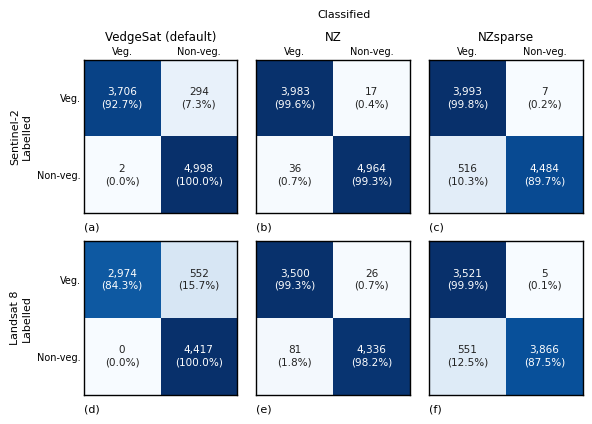

In [8]:
# =====================================================================================
# Confusion matrices figure (results 1.1). Run after the classifier metrics cell, or on its own: it reads
# classifier_metrics.csv from Data/Extra_analyses/Classifier_accuracy, so Section 5 need not be rerun.
# =====================================================================================
# One 2 x 2 matrix per classifier (columns) and platform (rows): labelled class down the side, classified
# class along the top. Each cell: pixel count, and in brackets the share of that labelled class (row %),
# so the diagonal is each class's recall. Shading follows the row %.
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

CM_DIR = os.path.join(filepath_data, 'Extra_analyses', 'Classifier_accuracy')   # filepath_data from Section 0
CM_PLATFORMS = ['S2', 'L8']                   # rows of the figure; add 'Both' for the pooled matrices
CM_MODELS = ['VedgeSat (default)', 'NZ', 'NZsparse']
CM_TITLES = {'VedgeSat (default)': 'VedgeSat (default)', 'NZ': 'NZ', 'NZsparse': 'NZsparse'}
CM_CMAP = 'Blues'
PLAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8', 'Both': 'Both platforms'}

M_cm = pd.read_csv(os.path.join(CM_DIR, 'classifier_metrics.csv')).set_index(['platform', 'model'])
nr, nc = len(CM_PLATFORMS), len(CM_MODELS)
fig, axes = plt.subplots(nr, nc, figsize=(1.95 * nc + 0.6, 1.95 * nr + 0.45), squeeze=False,
                         gridspec_kw=dict(wspace=0.12, hspace=0.18))
cmap = plt.get_cmap(CM_CMAP)
for i, plat in enumerate(CM_PLATFORMS):
    for j, model in enumerate(CM_MODELS):
        ax = axes[i, j]
        r = M_cm.loc[(plat, model)]
        counts = np.array([[r.TP, r.FN], [r.FP, r.TN]], dtype=float)     # rows: labelled veg, non-veg
        share = counts / counts.sum(axis=1, keepdims=True)
        ax.imshow(share, cmap=cmap, vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                dark = share[a, b] > 0.55
                ax.text(b, a, f'{int(counts[a, b]):,}\n({100 * share[a, b]:.1f}%)', ha='center', va='center',
                        fontsize=7.5, color='white' if dark else '#222222', linespacing=1.3)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(['Veg.', 'Non-veg.'] if i == 0 else ['', ''], fontsize=7)
        ax.set_yticklabels(['Veg.', 'Non-veg.'] if j == 0 else ['', ''], fontsize=7)
        ax.xaxis.set_ticks_position('top'); ax.tick_params(length=0, pad=2)
        for sp in ax.spines.values():
            sp.set_linewidth(1.0)
        ax.text(0.0, -0.06, f'({"abcdefghijkl"[i * nc + j]})', transform=ax.transAxes, fontsize=8, ha='left', va='top')
        if i == 0:
            ax.set_title(CM_TITLES[model], fontsize=8.5, pad=14)
        if j == 0:
            ax.set_ylabel(f'{PLAT_NAME[plat]}\nLabelled', fontsize=8, labelpad=4)
fig.text(0.53, 0.995, 'Classified', ha='center', va='top', fontsize=8)
png = os.path.join(CM_DIR, 'confusion_matrices.png')
fig.savefig(png, dpi=300, bbox_inches='tight')
fig.savefig(png.replace('.png', '.pdf'), bbox_inches='tight')
print('Saved', png, '(and .pdf)')
display(fig)
plt.close(fig)

## 6. Train final models and save

Both variants are trained on all training sites and saved alongside the originals, which are never overwritten. A JSON record of the configuration is saved next to each model for your methods.

In [50]:
for include_sparse, suffix in [(False, 'NZ'), (True, 'NZsparse')]:
    Xt, yt, mt = build_set(include_sparse=include_sparse, verbose=False)
    clf = new_mlp().fit(Xt, yt)
    name = f'MLPClassifier_Veg_L8S2_{suffix}'
    path = os.path.join(filepath_models, name + '.pkl')
    assert not os.path.basename(path).startswith('MLPClassifier_Veg_L5L8S2')
    joblib.dump(clf, path)
    record = {
        'model': name + '.pkl', 'created': datetime.now().isoformat(timespec='seconds'),
        'include_sparse': include_sparse, 'hidden_layer_sizes': HIDDEN, 'seed': SEED,
        'target_per_class': TARGET_PER_CLASS, 'shares': SHARES, 'platforms': PLATFORMS,
        'sites': {n: {'role': s['role'], 'bbox': s['bbox'], 'tile': s['tile'], 'scenes': s['scenes']}
                  for n, s in SITES.items()},
        'pixels': mt.groupby(['site', 'platform', 'subclass']).size().reset_index()
                    .rename(columns={0: 'n'}).to_dict('records'),
        'sklearn': sklearn.__version__,
    }
    with open(os.path.join(filepath_models, name + '.json'), 'w') as f:
        json.dump(record, f, indent=2, default=str)
    print('saved', path)

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Classification\models\MLPClassifier_Veg_L8S2_NZ.pkl
saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Classification\models\MLPClassifier_Veg_L8S2_NZsparse.pkl


To use a model, add `'veg_clf_model': 'MLPClassifier_Veg_L8S2_NZ.pkl'` (or `_NZsparse`) to the settings in your NZ driver notebook, alongside the `InitialiseImgs` wrapper. Check the extracted edges there with `check_detection`.